# Zajęcia 2 — Sprawozdanie

## 1. Import, dane, model

In [ ]:
import json, os, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)
seria = generuj_szereg()

def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno]); Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]   # [N, okno, 1]
    Y = np.array(Y, dtype=np.float32)[:, None]      # [N, 1]
    return X, Y

def przygotuj(okno):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8*len(X))
    return (torch.tensor(X[:n_tr]).to(DEVICE), torch.tensor(Y[:n_tr]).to(DEVICE),
            torch.tensor(X[n_tr:]).to(DEVICE), torch.tensor(Y[n_tr:]).to(DEVICE))

class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

Urządzenie: cpu


## 2. Pętla uczenia

In [2]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist_test, hist_train = [], []
    n = len(Xtr)
    for ep in range(epoki):
        model.train(); perm = torch.randperm(n)
        suma = 0.0
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            suma += loss.item() * len(idx)
        hist_train.append(suma / n)
        model.eval()
        with torch.no_grad():
            hist_test.append(strata(model(Xte), Yte).item())
    return hist_test, hist_train

## 3. Punkt odniesienia

In [3]:
Xtr, Ytr, Xte, Yte = przygotuj(30)
print('Trening:', tuple(Xtr.shape), ' Test:', tuple(Xte.shape))

torch.manual_seed(0)
baza = ModelRNN(hidden=32, typ='RNN')
h_te, h_tr = trenuj(baza, Xtr, Ytr, Xte, Yte, epoki=30)   # dokładnie jak w ćwiczeniu
print(f'Model bazowy RNN, hidden=32, OKNO=30, 30 epok:')
print(f'  test MSE: epoka 1 = {h_te[0]:.4f}, ostatnia epoka = {h_te[-1]:.4f}, mean(hist[-5:]) = {np.mean(h_te[-5:]):.4f}')
print(f'  train MSE (ostatnia epoka) = {h_tr[-1]:.4f}')

def mse_heurystyki(okno):
    _, _, Xt, Yt = przygotuj(okno)
    return ((Yt - Xt[:, -1])**2).mean().item()

print(f'Heurystyka „ostatnia próbka” (OKNO=30): MSE = {mse_heurystyki(30):.4f}')

Trening: (1576, 30, 1)  Test: (394, 30, 1)
Model bazowy RNN, hidden=32, OKNO=30, 30 epok:
  test MSE: epoka 1 = 0.0078, ostatnia epoka = 0.0038, mean(hist[-5:]) = 0.0039
  train MSE (ostatnia epoka) = 0.0039
Heurystyka „ostatnia próbka” (OKNO=30): MSE = 0.0063


## 4. Konfiguracja eksperymentów i funkcje pomocnicze

In [ ]:
EPOKI, LR, BATCH = 20, 1e-2, 64
SEEDS = (0, 1, 2)
STD_DDOF = 1
PLIK = 'wyniki.json'

WYNIKI = json.load(open(PLIK)) if os.path.exists(PLIK) else {}
_DANE = {}

def dane(okno):
    if okno not in _DANE:
        _DANE[okno] = przygotuj(okno)
    return _DANE[okno]

def klucz(typ, hidden, okno, seed):
    return f'{typ}|h{hidden}|w{okno}|s{seed}'

def uruchom(typ, hidden, okno):
    Xtr, Ytr, Xte, Yte = dane(okno)
    for s in SEEDS:
        k = klucz(typ, hidden, okno, s)
        if k in WYNIKI:
            continue
        torch.manual_seed(s)
        t0 = time.time()
        te, tr = trenuj(ModelRNN(hidden=hidden, typ=typ), Xtr, Ytr, Xte, Yte,
                        epoki=EPOKI, lr=LR, batch=BATCH)
        WYNIKI[k] = {'test': te, 'train': tr, 'score': float(np.mean(te[-5:])),
                     'train_score': float(np.mean(tr[-5:])), 'sek': time.time()-t0}
        json.dump(WYNIKI, open(PLIK, 'w'))
        print(f'  {k:22s} score={WYNIKI[k]["score"]:.4f}  ({WYNIKI[k]["sek"]:.1f}s)')

def podsumuj(typ, hidden, okno):
    sc = np.array([WYNIKI[klucz(typ, hidden, okno, s)]['score'] for s in SEEDS])
    tr = np.array([WYNIKI[klucz(typ, hidden, okno, s)]['train_score'] for s in SEEDS])
    return dict(typ=typ, hidden=hidden, okno=okno,
                test_mean=sc.mean(), test_std=sc.std(ddof=STD_DDOF),
                train_mean=tr.mean(), train_std=tr.std(ddof=STD_DDOF),
                heurystyka=mse_heurystyki(okno))

def krzywe(typ, hidden, okno, co='test'):
    M = np.array([WYNIKI[klucz(typ, hidden, okno, s)][co] for s in SEEDS])
    return M.mean(0), M.std(0, ddof=STD_DDOF)

def fmt(m, s): return f'{m:.4f} ± {s:.4f}'

## 5. Eksperyment A — liczba jednostek ukrytych
GRU, `OKNO=30`, `hidden ∈ {8, 16, 32, 64}`.

In [5]:
HID = [8, 16, 32, 64]
for h in HID:
    uruchom('GRU', h, 30)
A = pd.DataFrame([podsumuj('GRU', h, 30) for h in HID])
A['test MSE'] = [fmt(m, s) for m, s in zip(A.test_mean, A.test_std)]
A['train MSE'] = [fmt(m, s) for m, s in zip(A.train_mean, A.train_std)]
display(A[['hidden', 'test MSE', 'train MSE']].set_index('hidden'))
print(f'Heurystyka (OKNO=30): {A.heurystyka[0]:.4f}')

  GRU|h8|w30|s0          score=0.0038  (7.4s)
  GRU|h8|w30|s1          score=0.0037  (7.6s)
  GRU|h8|w30|s2          score=0.0038  (5.5s)
  GRU|h16|w30|s0         score=0.0037  (5.7s)
  GRU|h16|w30|s1         score=0.0038  (5.8s)
  GRU|h16|w30|s2         score=0.0037  (5.5s)
  GRU|h32|w30|s0         score=0.0038  (7.4s)
  GRU|h32|w30|s1         score=0.0037  (6.8s)
  GRU|h32|w30|s2         score=0.0038  (7.7s)
  GRU|h64|w30|s0         score=0.0039  (8.3s)
  GRU|h64|w30|s1         score=0.0037  (8.0s)
  GRU|h64|w30|s2         score=0.0037  (7.8s)


,test MSE,train MSE
hidden,,
8,0.0038 ± 0.0001,0.0037 ± 0.0001
16,0.0037 ± 0.0000,0.0037 ± 0.0001
32,0.0038 ± 0.0000,0.0036 ± 0.0001
64,0.0038 ± 0.0001,0.0035 ± 0.0000


Heurystyka (OKNO=30): 0.0063


## 6. Eksperyment B — długość okna
GRU, `hidden=32`, `OKNO ∈ {10, 30, 60, 120}`.

In [6]:
OKNA = [10, 30, 60, 120]
for w in OKNA:
    uruchom('GRU', 32, w)
B = pd.DataFrame([podsumuj('GRU', 32, w) for w in OKNA])
B['test MSE'] = [fmt(m, s) for m, s in zip(B.test_mean, B.test_std)]
B['train MSE'] = [fmt(m, s) for m, s in zip(B.train_mean, B.train_std)]
B['heurystyka'] = B.heurystyka.map(lambda v: f'{v:.4f}')
B['N test'] = [len(dane(w)[2]) for w in OKNA]
display(B[['okno', 'N test', 'test MSE', 'train MSE', 'heurystyka']].set_index('okno'))

  GRU|h32|w10|s0         score=0.0041  (3.1s)
  GRU|h32|w10|s1         score=0.0044  (3.0s)
  GRU|h32|w10|s2         score=0.0039  (2.8s)
  GRU|h32|w60|s0         score=0.0035  (12.3s)
  GRU|h32|w60|s1         score=0.0037  (12.0s)
  GRU|h32|w60|s2         score=0.0032  (12.0s)
  GRU|h32|w120|s0        score=0.0034  (22.5s)
  GRU|h32|w120|s1        score=0.0037  (22.7s)
  GRU|h32|w120|s2        score=0.0032  (22.5s)


,N test,test MSE,train MSE,heurystyka
okno,,,,
10,398,0.0041 ± 0.0002,0.0042 ± 0.0001,0.0063
30,394,0.0038 ± 0.0000,0.0036 ± 0.0001,0.0063
60,388,0.0034 ± 0.0003,0.0034 ± 0.0002,0.0063
120,376,0.0034 ± 0.0002,0.0034 ± 0.0002,0.0063


## 7. Eksperyment C — typ komórki
RNN / LSTM / GRU, `hidden=32`, dla skrajnych okien `OKNO ∈ {10, 120}`.

In [7]:
TYPY = ['RNN', 'LSTM', 'GRU']
for w in (10, 120):
    for typ in TYPY:
        uruchom(typ, 32, w)
C = pd.DataFrame([podsumuj(t, 32, w) for w in (10, 120) for t in TYPY])
C['test MSE'] = [fmt(m, s) for m, s in zip(C.test_mean, C.test_std)]
C['train MSE'] = [fmt(m, s) for m, s in zip(C.train_mean, C.train_std)]
# epoka, od której uśredniona krzywa testowa schodzi poniżej heurystyki (miara szybkości uczenia)
def ep_poniżej(typ, w):
    m, _ = krzywe(typ, 32, w)
    i = np.where(m < mse_heurystyki(w))[0]
    return int(i[0]) + 1 if len(i) else None
C['epoka < heurystyki'] = [ep_poniżej(t, w) for w in (10, 120) for t in TYPY]
display(C[['okno', 'typ', 'test MSE', 'train MSE', 'epoka < heurystyki']].set_index(['okno', 'typ']))

  RNN|h32|w10|s0         score=0.0043  (1.6s)
  RNN|h32|w10|s1         score=0.0044  (1.5s)
  RNN|h32|w10|s2         score=0.0038  (1.5s)
  LSTM|h32|w10|s0        score=0.0043  (1.5s)
  LSTM|h32|w10|s1        score=0.0041  (1.5s)
  LSTM|h32|w10|s2        score=0.0040  (1.5s)
  RNN|h32|w120|s0        score=0.0040  (9.0s)
  RNN|h32|w120|s1        score=0.0040  (9.0s)
  RNN|h32|w120|s2        score=0.0040  (9.0s)
  LSTM|h32|w120|s0       score=0.0039  (4.9s)
  LSTM|h32|w120|s1       score=0.0036  (5.0s)
  LSTM|h32|w120|s2       score=0.0037  (4.7s)


test MSE        train MSE  epoka < heurystyki
okno typ                                                       
10   RNN   0.0042 ± 0.0003  0.0043 ± 0.0001                   2
     LSTM  0.0042 ± 0.0001  0.0041 ± 0.0000                   3
     GRU   0.0041 ± 0.0002  0.0042 ± 0.0001                   2
120  RNN   0.0040 ± 0.0000  0.0041 ± 0.0001                   2
     LSTM  0.0037 ± 0.0002  0.0039 ± 0.0002                   2
     GRU   0.0034 ± 0.0002  0.0034 ± 0.0002                   2

## 8. Krzywe uczenia
Linie ciągłe — test, przerywane — trening (średnia z 3 ziaren, cień = ±1 odch. std. dla testu). Pozioma kropkowana linia = heurystyka „ostatnia próbka”.

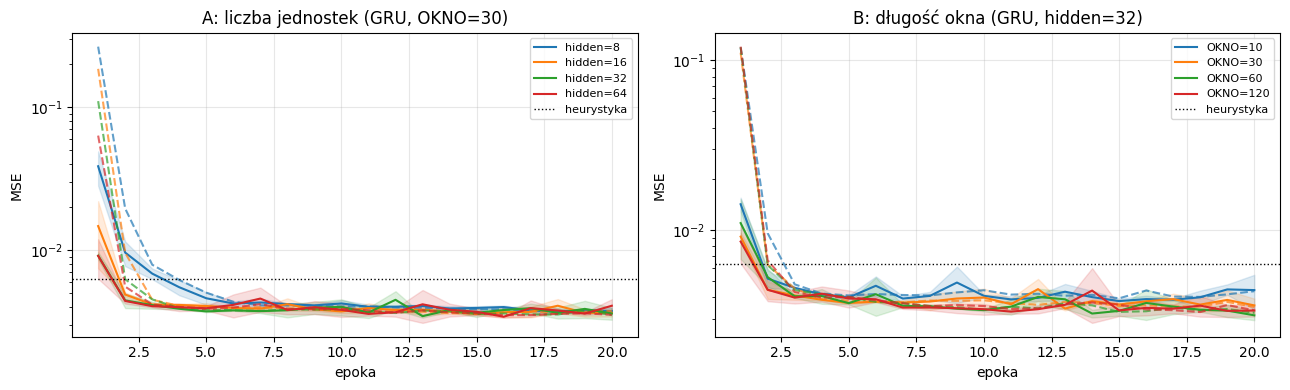

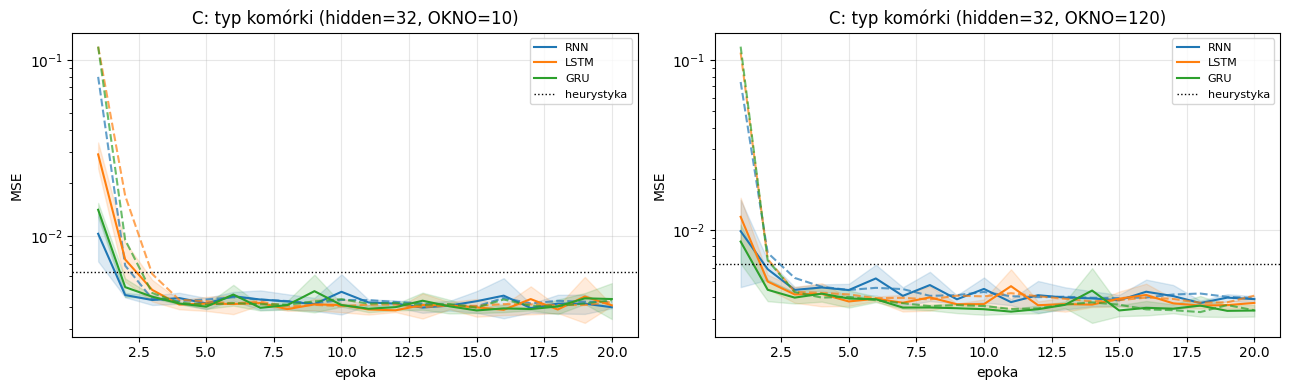

In [8]:
ep = np.arange(1, EPOKI+1)
def rysuj(ax, konf, etykiety, okno_h, tytul):
    for (typ, h, w), et in zip(konf, etykiety):
        m, s = krzywe(typ, h, w, 'test'); mt, _ = krzywe(typ, h, w, 'train')
        l, = ax.plot(ep, m, label=et)
        ax.fill_between(ep, m-s, m+s, alpha=0.15, color=l.get_color())
        ax.plot(ep, mt, '--', color=l.get_color(), alpha=0.7)
    ax.axhline(mse_heurystyki(okno_h), color='k', ls=':', lw=1, label='heurystyka')
    ax.set_yscale('log'); ax.set_xlabel('epoka'); ax.set_ylabel('MSE'); ax.set_title(tytul)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
rysuj(ax[0], [('GRU', h, 30) for h in HID], [f'hidden={h}' for h in HID], 30, 'A: liczba jednostek (GRU, OKNO=30)')
rysuj(ax[1], [('GRU', 32, w) for w in OKNA], [f'OKNO={w}' for w in OKNA], 30, 'B: długość okna (GRU, hidden=32)')
plt.tight_layout(); plt.savefig('krzywe_AB.png', dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, w in zip(ax, (10, 120)):
    rysuj(a, [(t, 32, w) for t in TYPY], TYPY, w, f'C: typ komórki (hidden=32, OKNO={w})')
plt.tight_layout(); plt.savefig('krzywe_C.png', dpi=150); plt.show()

## 9. Wyniki zbiorcze
Poniższa komórka drukuje wszystkie tabele w formacie Markdown
i zapisuje je do `tabele.md`.

In [9]:
def do_md(df, cols):
    out = '| ' + ' | '.join(cols) + ' |\n|' + '---|'*len(cols) + '\n'
    for _, r in df.iterrows():
        out += '| ' + ' | '.join(str(r[c]) for c in cols) + ' |\n'
    return out

tekst  = '### Punkt odniesienia\n'
tekst += f'- RNN, hidden=32, OKNO=30, 30 epok (ćwiczenie): test MSE = {h_te[-1]:.4f} (ostatnia epoka), {np.mean(h_te[-5:]):.4f} (średnia z 5 ostatnich epok)\n'
tekst += f'- Heurystyka „ostatnia próbka” (OKNO=30): {mse_heurystyki(30):.4f}\n\n'
tekst += '### Eksperyment A (GRU, OKNO=30)\n' + do_md(A, ['hidden', 'test MSE', 'train MSE']) + '\n'
tekst += '### Eksperyment B (GRU, hidden=32)\n' + do_md(B, ['okno', 'N test', 'test MSE', 'train MSE', 'heurystyka']) + '\n'
tekst += '### Eksperyment C (hidden=32)\n' + do_md(C, ['okno', 'typ', 'test MSE', 'train MSE', 'epoka < heurystyki']) + '\n'
print(tekst)
open('tabele.md', 'w').write(tekst)

### Punkt odniesienia
- RNN, hidden=32, OKNO=30, 30 epok (ćwiczenie): test MSE = 0.0038 (ostatnia epoka), 0.0039 (średnia z 5 ostatnich epok)
- Heurystyka „ostatnia próbka” (OKNO=30): 0.0063

### Eksperyment A (GRU, OKNO=30)
| hidden | test MSE | train MSE |
|---|---|---|
| 8 | 0.0038 ± 0.0001 | 0.0037 ± 0.0001 |
| 16 | 0.0037 ± 0.0000 | 0.0037 ± 0.0001 |
| 32 | 0.0038 ± 0.0000 | 0.0036 ± 0.0001 |
| 64 | 0.0038 ± 0.0001 | 0.0035 ± 0.0000 |

### Eksperyment B (GRU, hidden=32)
| okno | N test | test MSE | train MSE | heurystyka |
|---|---|---|---|---|
| 10 | 398 | 0.0041 ± 0.0002 | 0.0042 ± 0.0001 | 0.0063 |
| 30 | 394 | 0.0038 ± 0.0000 | 0.0036 ± 0.0001 | 0.0063 |
| 60 | 388 | 0.0034 ± 0.0003 | 0.0034 ± 0.0002 | 0.0063 |
| 120 | 376 | 0.0034 ± 0.0002 | 0.0034 ± 0.0002 | 0.0063 |

### Eksperyment C (hidden=32)
| okno | typ | test MSE | train MSE | epoka < heurystyki |
|---|---|---|---|---|
| 10 | RNN | 0.0042 ± 0.0003 | 0.0043 ± 0.0001 | 2 |
| 10 | LSTM | 0.0042 ± 0.0001 | 0.0041 ± 0.000

1225